In [1]:
from pathlib import Path

import pandas as pd

# the data is in eda/old_ag_news_csv/; this works whether the notebook starts in eda/ or in the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
DATA = ROOT / 'eda' / 'old_ag_news_csv'

train_df = pd.read_csv(DATA / 'train.csv', names=['class', 'title', 'description'])
test_df = pd.read_csv(DATA / 'test.csv', names=['class', 'title', 'description'])
train_df.head()

,class,title,description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


### Klasy


| ID | Nazwa |
| -------- | -------- |
| 1 | World |
| 2 | Sports |
| 3 | Business |
| 4 | Sci/Tech |

In [2]:
classes = {
    1: 'World', 
    2: 'Sports', 
    3: 'Business', 
    4: 'Sci/Tech'
}

### Dystrybucja klas na zbiorze treningowym

In [3]:
train_df['class'].value_counts()

class
3    30000
4    30000
2    30000
1    30000
Name: count, dtype: int64

### Dystrybucja klas na zbiorze testowym

In [4]:
test_df['class'].value_counts()

class
3    1900
4    1900
2    1900
1    1900
Name: count, dtype: int64

In [5]:
import re

import matplotlib.pyplot as plt
from wordcloud import STOPWORDS, WordCloud


def clean_text(text):
    text = re.sub(r'[^A-Za-z\s]', '', text) 

    text = text.lower()

    stopwords = set(STOPWORDS)
    return ' '.join(word for word in text.split() if word not in stopwords)


def generate_wordcloud(text):

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.show()

## Wszystkie klasy razem

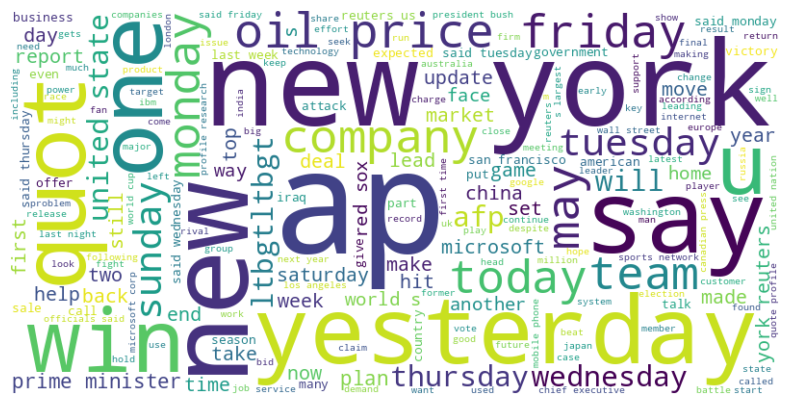

In [6]:
text_titles = clean_text(' '.join(train_df['title'].astype(str).tolist()))
text_desc = clean_text(' '.join(train_df['description'].astype(str).tolist()))
text_all = text_titles + ' ' + text_desc
generate_wordcloud(text_all)

In [7]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer


def get_top_bottom(text_titles, text_desc, text_all):
    bow_titles_vectorizer = CountVectorizer()
    bow_titles = bow_titles_vectorizer.fit_transform([text_titles])
    bow_titles = bow_titles.toarray()[0]

    bow_desc_vectorizer = CountVectorizer()
    bow_desc = bow_desc_vectorizer.fit_transform([text_desc])
    bow_desc = bow_desc.toarray()[0]

    bow_all_vectorizer = CountVectorizer()
    bow_all = bow_all_vectorizer.fit_transform([text_all])
    bow_all = bow_all.toarray()[0]

    top_titles_words = bow_titles_vectorizer.get_feature_names_out()[np.argpartition(bow_titles, -10)[-10:]]
    bottom_titles_words = bow_titles_vectorizer.get_feature_names_out()[np.argpartition(bow_titles, 10)[:10]]

    top_desc_words = bow_desc_vectorizer.get_feature_names_out()[np.argpartition(bow_desc, -10)[-10:]]
    bottom_desc_words = bow_desc_vectorizer.get_feature_names_out()[np.argpartition(bow_desc, 10)[:10]]

    top_all_words = bow_all_vectorizer.get_feature_names_out()[np.argpartition(bow_all, -10)[-10:]]
    bottom_all_words = bow_all_vectorizer.get_feature_names_out()[np.argpartition(bow_all, 10)[:10]]

    return pd.DataFrame({
        "Top Title": top_titles_words,
        "Bottom Title": bottom_titles_words,
        "Top Description": top_desc_words,
        "Bottom Description": bottom_desc_words,
        "Top All": top_all_words,
        "Bottom All": bottom_all_words,
    })

get_top_bottom(text_titles, text_desc, text_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,update,exstudent,wednesday,moreshares,monday,mmoire
1,iraq,exstate,ap,mores,will,mmn
2,says,exteammate,new,morestorage,two,mncs
3,microsoft,exteam,two,moreso,ap,mnbas
4,oil,peugeotcitroen,us,moresharply,reuters,mmoires
5,new,ext,will,morethe,world,mnyandu
6,ltbgtltbgt,exteledata,reuters,moresafely,first,mmode
7,reuters,pft,first,moreor,us,mmediately
8,us,pfy,said,morepositive,new,mmilliondollar
9,ap,exspain,monday,moreto,said,moan


## Klasa "World"

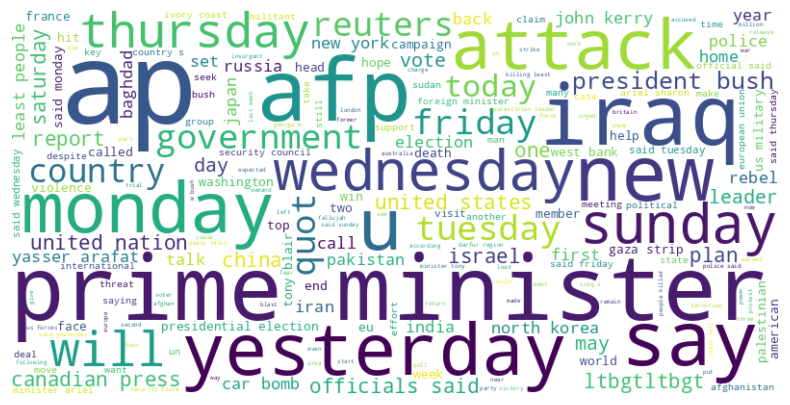

In [8]:
df = train_df[train_df['class'] == 1]
text_world_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_world_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_world_all = text_world_titles + ' ' + text_world_desc
generate_wordcloud(text_world_all)

In [9]:
get_top_bottom(text_world_titles, text_world_desc, text_world_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,new,mandelas,new,midsized,minister,medallist
1,ltbgtltbgt,maneuvering,people,midsentence,two,med
2,bush,malta,two,midyear,president,medicaid
3,un,mammoth,ap,midwifery,iraq,mediasavvy
4,ap,manage,us,midwife,afp,mediasaid
5,us,managing,reuters,midwesterners,us,mediareported
6,reuters,manchester,minister,midway,ap,median
7,says,mandatory,said,midterm,reuters,medea
8,afp,malki,president,midsummer,new,medavoy
9,iraq,mania,iraq,miers,said,medicarehealth


## Klasa "Sports"

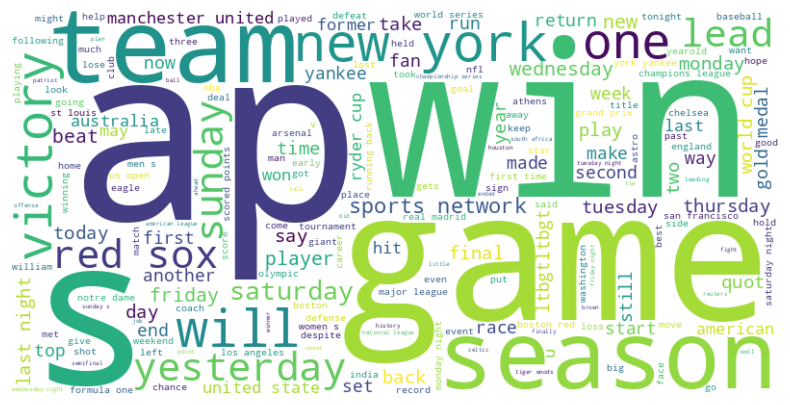

In [10]:
df = train_df[train_df['class'] == 2]
text_sports_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_sports_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_sports_all = text_sports_titles + ' ' + text_sports_desc
generate_wordcloud(text_sports_all)

In [11]:
get_top_bottom(text_sports_titles, text_sports_desc, text_sports_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,lead,fling,world,mcintosh,world,matchtypes
1,new,flingers,last,mcingvale,night,matchless
2,cup,flexor,team,mcl,team,mateu
3,us,problemhit,game,mckinnon,season,mateschitzs
4,game,problema,night,mckenzies,will,materialized
5,ltbgtltbgt,probes,ap,mckee,win,materialises
6,ap,flexes,will,mckale,game,materazzi
7,wins,flipped,new,mcintyre,ap,mateen
8,win,prmont,first,mcmeans,new,mathematical
9,sox,proceeding,season,mchugh,first,matchreferee


## Klasa "Business"

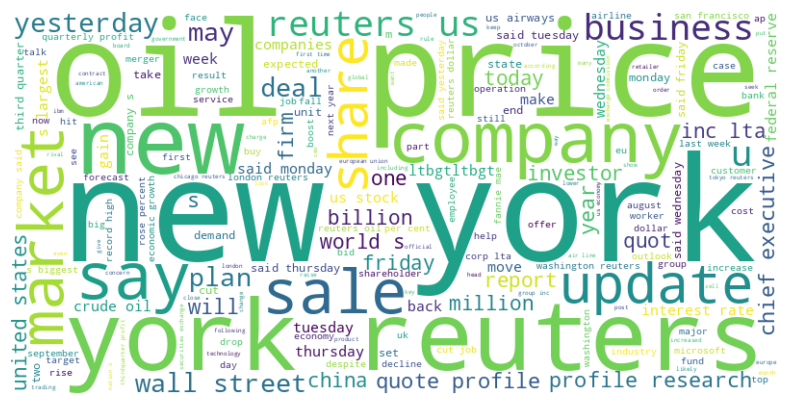

In [12]:
df = train_df[train_df['class'] == 3]
text_business_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_business_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_business_all = text_business_titles + ' ' + text_business_desc
generate_wordcloud(text_business_all)

In [13]:
get_top_bottom(text_business_titles, text_business_desc, text_business_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,deal,indias,prices,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,percent,hangup
1,new,indicates,york,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,will,rockland
2,prices,indiagames,company,hrl,oil,hansens
3,profit,indianabased,will,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,us,rockclimbing
4,update,indians,oil,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,inc,hannover
5,sales,indiapakistan,reuters,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,prices,hannes
6,us,indiaasean,inc,softwarerelated,reuters,hanker
7,reuters,indicate,new,hsbal,company,rocbox
8,oil,individuals,us,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,said,hangars
9,stocks,indies,said,hrefhttpwwwinvestorreuterscomfullquoteaspxtick...,new,rockribbed


## Klasa "Sci/Tech"

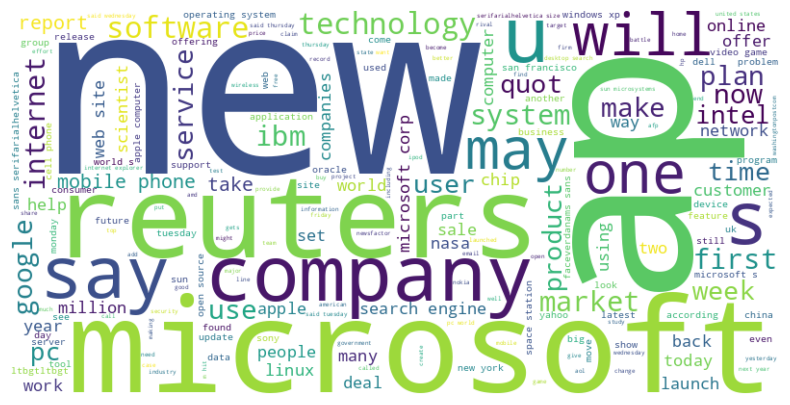

In [14]:
df = train_df[train_df['class'] == 4]
text_tech_titles = clean_text(' '.join(df['title'].astype(str).tolist()))
text_tech_desc = clean_text(' '.join(df['description'].astype(str).tolist()))
text_tech_all = text_tech_titles + ' ' + text_tech_desc
generate_wordcloud(text_tech_all)

In [15]:
get_top_bottom(text_tech_titles, text_tech_desc, text_tech_all)

,Top Title,Bottom Title,Top Description,Bottom Description,Top All,Bottom All
0,security,ministerial,reuters,muchvaunted,us,moores
1,space,ministers,ap,muchwill,internet,moots
2,intel,minimo,company,muchtalkedabout,reuters,moontitan
3,search,minimotions,inc,muchthis,company,moony
4,google,minimouse,internet,muchto,software,moor
5,ibm,minimum,software,muchhypedfuel,said,moonlighting
6,ap,minis,new,mugshot,will,moorhen
7,new,miniscule,microsoft,mugged,ap,mopped
8,reuters,minisized,will,muchearlier,microsoft,mopheus
9,microsoft,minimal,said,muffled,new,moonless


## Separowalność Klas

### Bag of Words

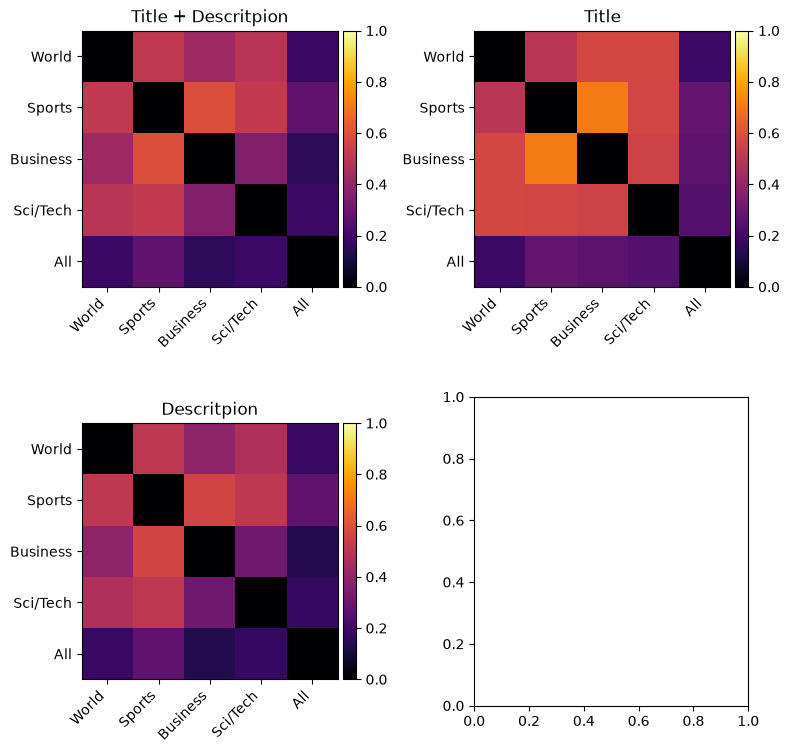

In [16]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics import pairwise_distances


def pairwise_plot(texts, vectorizer, ax):
    labels = list(classes.values()) + ['All']
    X = vectorizer.fit_transform(texts)
    dist = pairwise_distances(X, metric='cosine')
    im = ax.imshow(dist, interpolation='none', vmin=0, vmax=1, cmap='inferno')
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticklabels(labels)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    ax.figure.colorbar(im, cax=cax, orientation="vertical")

fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].set_title('Title + Descritpion')
pairwise_plot(
    [text_world_all, text_sports_all, text_business_all, text_tech_all, text_all], 
    CountVectorizer(),
    ax[0][0]
)

ax[0][1].set_title('Title')
pairwise_plot(
    [text_world_titles, text_sports_titles, text_business_titles, text_tech_titles, text_titles], 
    CountVectorizer(),
    ax[0][1]
)

ax[1][0].set_title('Descritpion')
pairwise_plot(
    [text_world_desc, text_sports_desc, text_business_desc, text_tech_desc, text_desc], 
    CountVectorizer(),
    ax[1][0]
)

fig.tight_layout()
plt.show()

### Binary Bag of Words

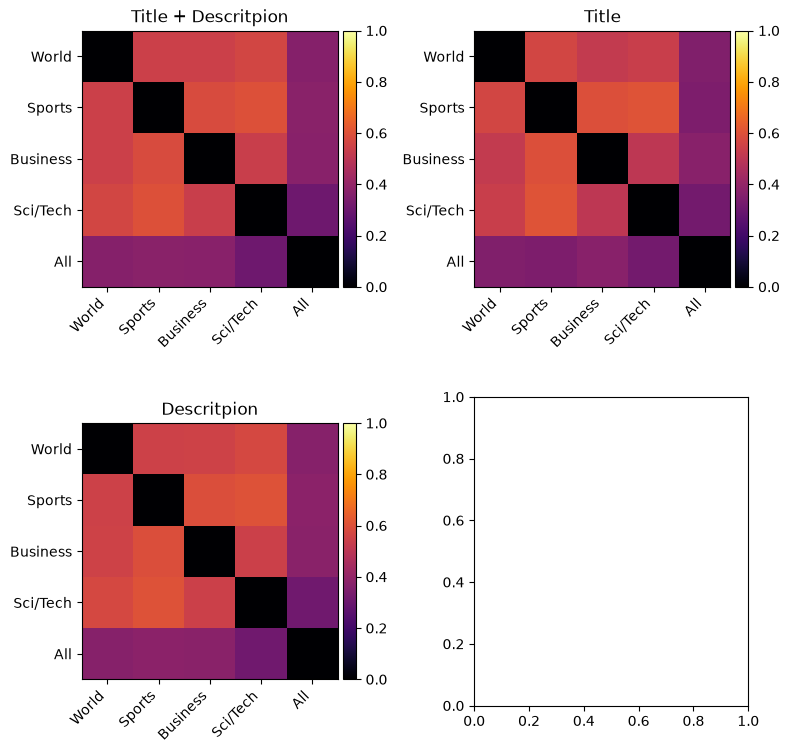

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].set_title('Title + Descritpion')
pairwise_plot(
    [text_world_all, text_sports_all, text_business_all, text_tech_all, text_all], 
    CountVectorizer(binary=True),
    ax[0][0]
)

ax[0][1].set_title('Title')
pairwise_plot(
    [text_world_titles, text_sports_titles, text_business_titles, text_tech_titles, text_titles], 
    CountVectorizer(binary=True),
    ax[0][1]
)

ax[1][0].set_title('Descritpion')
pairwise_plot(
    [text_world_desc, text_sports_desc, text_business_desc, text_tech_desc, text_desc], 
    CountVectorizer(binary=True),
    ax[1][0]
)

fig.tight_layout()
plt.show()

### Tf-Idf

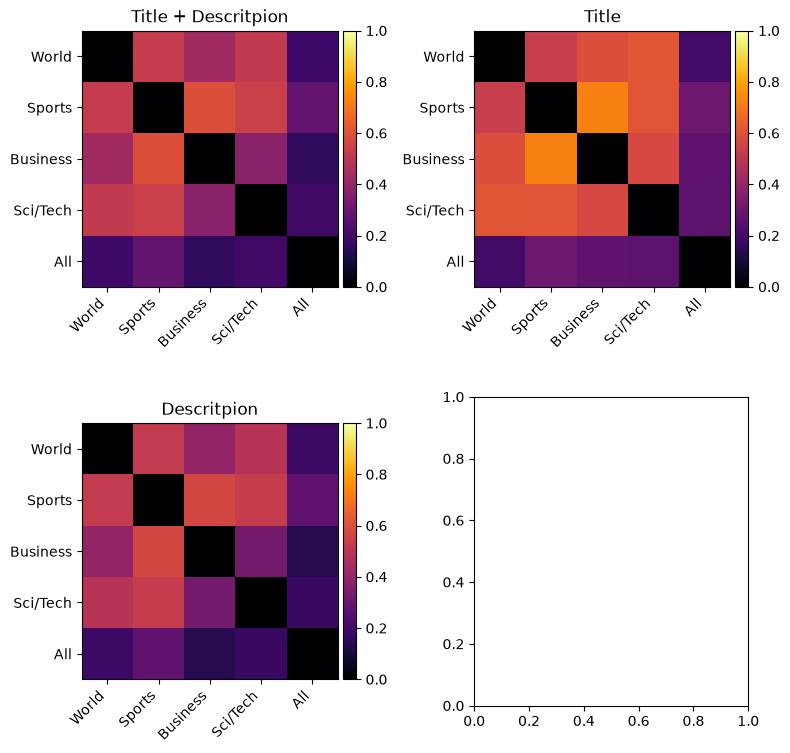

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].set_title('Title + Descritpion')
pairwise_plot(
    [text_world_all, text_sports_all, text_business_all, text_tech_all, text_all], 
    TfidfVectorizer(),
    ax[0][0]
)

ax[0][1].set_title('Title')
pairwise_plot(
    [text_world_titles, text_sports_titles, text_business_titles, text_tech_titles, text_titles], 
    TfidfVectorizer(),
    ax[0][1]
)

ax[1][0].set_title('Descritpion')
pairwise_plot(
    [text_world_desc, text_sports_desc, text_business_desc, text_tech_desc, text_desc], 
    TfidfVectorizer(),
    ax[1][0]
)

fig.tight_layout()
plt.show()

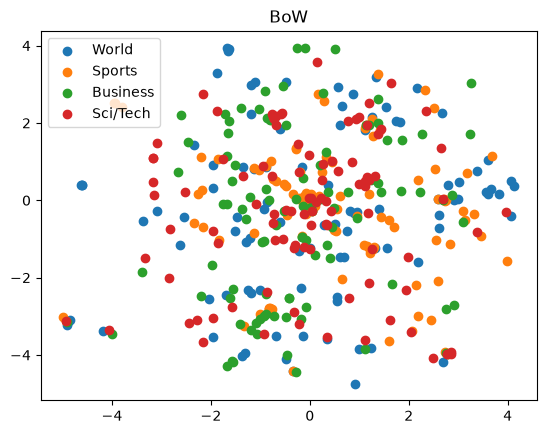

In [19]:
from sklearn.manifold import TSNE

small_df = pd.concat([
    train_df[train_df['class'] == 1].sample(100, random_state=1),
    train_df[train_df['class'] == 2].sample(100, random_state=1),
    train_df[train_df['class'] == 3].sample(100, random_state=1),
    train_df[train_df['class'] == 4].sample(100, random_state=1),
])

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(small_df['title'])
X_embedded = TSNE(n_components=2).fit_transform(X)

for c, c_name in classes.items():
    x = X_embedded[small_df['class'] == c, 0]
    y = X_embedded[small_df['class'] == c, 1]
    plt.scatter(x, y, label=c_name)
plt.title('BoW')
plt.legend()

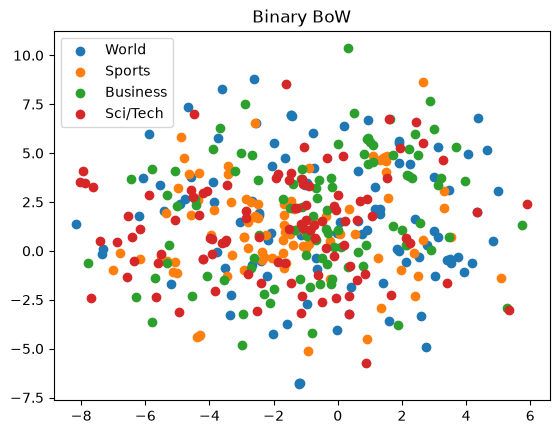

In [20]:
vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(small_df['title'])
X_embedded = TSNE(n_components=2).fit_transform(X)

for c, c_name in classes.items():
    x = X_embedded[small_df['class'] == c, 0]
    y = X_embedded[small_df['class'] == c, 1]
    plt.scatter(x, y, label=c_name)
plt.title('Binary BoW')
plt.legend()

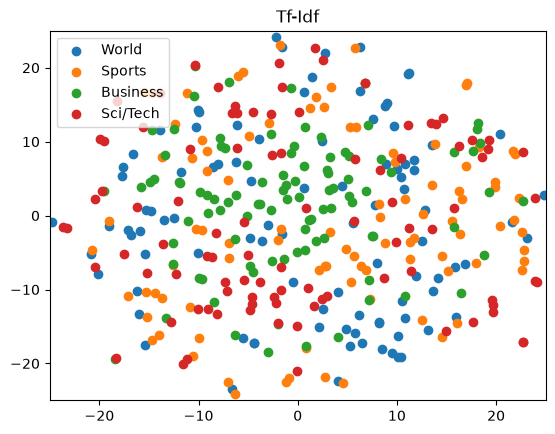

In [21]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(small_df['title'])
X_embedded = TSNE(n_components=2).fit_transform(X)

for c, c_name in classes.items():
    x = X_embedded[small_df['class'] == c, 0]
    y = X_embedded[small_df['class'] == c, 1]
    plt.scatter(x, y, label=c_name)
plt.title('Tf-Idf')
plt.xlim(-25, 25)
plt.ylim(-25, 25)
plt.legend()

## Artefakty

In [22]:
from collections import Counter

import nltk
from nltk.corpus import gutenberg

nltk.download('gutenberg')
words = {str(word).lower() for word in gutenberg.words()}

Counter(word for word in text_all.split(' ') if word not in words)

[nltk_data] Downloading package gutenberg to
[nltk_data]     /home/nr6000000/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


Counter({'reuters': 17243,
         'ap': 16148,
         'inc': 6537,
         'iraq': 5886,
         'microsoft': 5585,
         'corp': 4821,
         'afp': 4522,
         'percent': 4482,
         'quot': 4402,
         'internet': 3865,
         'technology': 2874,
         'ltbgtltbgt': 2559,
         'iraqi': 2478,
         'update': 2430,
         'google': 2421,
         'ibm': 2399,
         'baghdad': 2214,
         'wireless': 2081,
         'lta': 2032,
         'nuclear': 1997,
         'phone': 1958,
         'palestinian': 1902,
         'sox': 1870,
         'olympic': 1800,
         'global': 1779,
         'israeli': 1771,
         'intel': 1737,
         'investors': 1720,
         'iran': 1602,
         'eu': 1534,
         'peoplesoft': 1511,
         'uk': 1509,
         'pakistan': 1496,
         'video': 1495,
         'pc': 1479,
         'championship': 1429,
         'linux': 1377,
         'tokyo': 1362,
         'digital': 1337,
         'nasa': 1332,
   

Cel biznesowy:
Klasyfikator wiadomości na platformie typu agregator wiadomości (dobór reklam, sugerowanie innych artykułow, tworzenie zbiorczych zestawień tematycznych).

Hipotezy:
- Usunięcie artefaktów HTML poprawi klasyfikację wiadomości
- Usunięcie stopwordów poprawi klasyfikację wiadomości
- Same tytuły będą dawały lepsze wyniki w prostych metodach niż połączenie tytułów i opisów
- Tf-Idf będzie skuteczny w separacji klas